In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import ks_2samp
import warnings
warnings.filterwarnings('ignore')

print("\n=======================================================")
print("🧠 PHASE 3: HUẤN LUYỆN CORE MODEL (XGBOOST DEEP TREE)")
print("=======================================================\n")

# 1. LOAD DATA TỪ FILE GOLD (Đảm bảo chuẩn MLOps)
print("Đang tải dữ liệu Vàng (Train & Val)...")
df_train_gold = pd.read_parquet("D:/XAI_risk_score/data/gold/train_gold.parquet")
df_val_gold = pd.read_parquet("D:/XAI_risk_score/data/gold/val_gold.parquet")

X_train_xgb = df_train_gold.drop(columns=['target'])
y_train_xgb = df_train_gold['target']

X_val_xgb = df_val_gold.drop(columns=['target'])
y_val_xgb = df_val_gold['target']

# 2. TÍNH TOÁN HỆ SỐ MẤT CÂN BẰNG
n_good = (y_train_xgb == 0).sum()
n_bad = (y_train_xgb == 1).sum()
scale_weight = n_good / n_bad
print(f"-> Phân bổ tập Train: {n_good} Tốt | {n_bad} Xấu")
print(f"-> Hệ số phạt mất cân bằng (scale_pos_weight) : {scale_weight:.2f}")

# 3. THIẾT LẬP MÔ HÌNH XGBOOST (PHÒNG THỦ CAO)
clf_xgb = xgb.XGBClassifier(
    n_estimators=1500,           # Cho tối đa 1500 cây (dư sức vì có early stopping)
    max_depth=6,                 # Chiều sâu 6: Đủ sâu để học tương tác phức tạp
    learning_rate=0.03,          # Tốc độ học chậm -> Mô hình hội tụ từ từ, chắc chắn

    # --- NHÓM XỬ LÝ MẤT CÂN BẰNG & CHỐNG OVERFITTING ---
    scale_pos_weight=scale_weight,
    min_child_weight=50,         # Tránh tạo lá (leaf) chứa quá ít mẫu nợ xấu
    subsample=0.8,               # Lấy ngẫu nhiên 80% data mỗi cây (hoặc 60%)
    colsample_bytree=0.8,        # Lấy ngẫu nhiên 80% features mỗi cây (hoặc 60%)
    reg_alpha=0.5,               # L1 Regularization (Xóa nhiễu)
    reg_lambda=1.5,              # L2 Regularization (Làm mượt trọng số)

    eval_metric='auc',           # Dùng AUC làm thước đo validation
    early_stopping_rounds=50,    # Dừng nếu AUC trên tập Val không tăng sau 50 vòng
    random_state=42,
    n_jobs=-1
)

# 4. HUẤN LUYỆN
print("\nĐang huấn luyện XGBoost... (Khá nặng, có thể mất 1 - 3 phút)")
clf_xgb.fit(
    X_train_xgb, y_train_xgb,
    eval_set=[(X_train_xgb, y_train_xgb), (X_val_xgb, y_val_xgb)],
    verbose=50 # In log mỗi 50 vòng
)

print(f"\n-> Mô hình hội tụ và dừng sớm tại cây thứ: {clf_xgb.best_iteration}")

# 5. ĐÁNH GIÁ CHẤT LƯỢNG MÔ HÌNH (Trên tập Validation)
y_val_prob_xgb = clf_xgb.predict_proba(X_val_xgb)[:, 1]

auc_xgb = roc_auc_score(y_val_xgb, y_val_prob_xgb)
gini_xgb = 2 * auc_xgb - 1
pr_auc_xgb = average_precision_score(y_val_xgb, y_val_prob_xgb)
ks_stat_xgb, _ = ks_2samp(y_val_prob_xgb[y_val_xgb == 1], y_val_prob_xgb[y_val_xgb == 0])

print("\n🏆 --- KẾT QUẢ ĐÁNH GIÁ XGBOOST (CORE MODEL) ---")
print(f"🎯 ROC-AUC      : {auc_xgb:.4f}")
print(f"🎯 Gini         : {gini_xgb:.4f} (Mong đợi > 0.60)")
print(f"🎯 PR-AUC       : {pr_auc_xgb:.4f}")
print(f"🎯 KS Statistic : {ks_stat_xgb:.4f}")

# 6. LƯU LẠI MÔ HÌNH
clf_xgb.save_model("D:/XAI_risk_score/model_artifacts/xgboost_core_model.json")
print("\n✅ Đã lưu bộ não XGBoost vào 'model_artifacts/xgboost_core_model.json'")


🧠 PHASE 3: HUẤN LUYỆN CORE MODEL (XGBOOST DEEP TREE)

Đang tải dữ liệu Vàng (Train & Val)...
-> Phân bổ tập Train: 323437 Tốt | 11023 Xấu
-> Hệ số phạt mất cân bằng (scale_pos_weight) : 29.34

Đang huấn luyện XGBoost... (Khá nặng, có thể mất 1 - 3 phút)
[0]	validation_0-auc:0.73107	validation_1-auc:0.72250
[50]	validation_0-auc:0.80685	validation_1-auc:0.78958
[100]	validation_0-auc:0.82039	validation_1-auc:0.79756
[150]	validation_0-auc:0.82858	validation_1-auc:0.80052
[200]	validation_0-auc:0.83497	validation_1-auc:0.80208
[250]	validation_0-auc:0.84006	validation_1-auc:0.80320
[300]	validation_0-auc:0.84431	validation_1-auc:0.80402
[350]	validation_0-auc:0.84829	validation_1-auc:0.80452
[400]	validation_0-auc:0.85229	validation_1-auc:0.80509
[450]	validation_0-auc:0.85644	validation_1-auc:0.80525
[500]	validation_0-auc:0.85982	validation_1-auc:0.80515
[504]	validation_0-auc:0.86015	validation_1-auc:0.80521

-> Mô hình hội tụ và dừng sớm tại cây thứ: 454

🏆 --- KẾT QUẢ ĐÁNH GIÁ XGBO

In [4]:
import pandas as pd
import xgboost as xgb
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import ks_2samp

print("\n=======================================================")
print("⚖️ PHASE 3.5: ĐÁNH GIÁ CHUNG CUỘC TRÊN TẬP TEST (BLIND TEST)")
print("=======================================================\n")

# 1. LOAD TẬP TEST VÀNG (Chưa từng được mô hình nhìn thấy)
print("Đang tải dữ liệu Test Vàng...")
df_test_gold = pd.read_parquet("D:/XAI_risk_score/data/gold/test_gold.parquet")

X_test = df_test_gold.drop(columns=['target'])
y_test = df_test_gold['target']

# 2. LOAD LẠI MÔ HÌNH TỪ Ổ CỨNG (Kiểm tra luôn tính toàn vẹn của file model)
print("Đang tải bộ não XGBoost từ ổ cứng...")
loaded_model = xgb.XGBClassifier()
loaded_model.load_model("D:/XAI_risk_score/model_artifacts/xgboost_core_model.json")

# 3. DỰ ĐOÁN XÁC SUẤT TRÊN TẬP TEST
print("Đang tiến hành dự đoán...")
y_test_prob = loaded_model.predict_proba(X_test)[:, 1]

# 4. TÍNH TOÁN CÁC CHỈ SỐ
auc_test = roc_auc_score(y_test, y_test_prob)
gini_test = 2 * auc_test - 1
pr_auc_test = average_precision_score(y_test, y_test_prob)
ks_stat_test, _ = ks_2samp(y_test_prob[y_test == 1], y_test_prob[y_test == 0])

# 5. IN KẾT QUẢ SO SÁNH VỚI VALIDATION
# (Lấy lại kết quả Val cũ để so sánh trực quan)
val_gini = 0.6106 # Điểm của bạn ở bước trước
val_ks = 0.4625

print("\n🏆 --- KẾT QUẢ FINAL BLIND TEST ---")
print(f"🎯 ROC-AUC      : {auc_test:.4f}")
print(f"🎯 Gini         : {gini_test:.4f} (Độ lệch so với Val: {(gini_test - val_gini):.4f})")
print(f"🎯 PR-AUC       : {pr_auc_test:.4f}")
print(f"🎯 KS Statistic : {ks_stat_test:.4f} (Độ lệch so với Val: {(ks_stat_test - val_ks):.4f})")

# 6. NHẬN XÉT TỰ ĐỘNG
if abs(gini_test - val_gini) < 0.03:
    print("\n✅ KẾT LUẬN: TUYỆT VỜI! Mô hình cực kỳ ỔN ĐỊNH. Không có dấu hiệu Overfitting.")
    print("Hệ thống đã sẵn sàng 100% để chuyển sang Phase Explainable AI (SHAP)!")
else:
    print("\n⚠️ CẢNH BÁO: Có sự chênh lệch lớn giữa Train/Val và Test. Cần kiểm tra lại Data Leakage!")


⚖️ PHASE 3.5: ĐÁNH GIÁ CHUNG CUỘC TRÊN TẬP TEST (BLIND TEST)

Đang tải dữ liệu Test Vàng...
Đang tải bộ não XGBoost từ ổ cứng...
Đang tiến hành dự đoán...

🏆 --- KẾT QUẢ FINAL BLIND TEST ---
🎯 ROC-AUC      : 0.8046
🎯 Gini         : 0.6093 (Độ lệch so với Val: -0.0013)
🎯 PR-AUC       : 0.1568
🎯 KS Statistic : 0.4644 (Độ lệch so với Val: 0.0019)

✅ KẾT LUẬN: TUYỆT VỜI! Mô hình cực kỳ ỔN ĐỊNH. Không có dấu hiệu Overfitting.
Hệ thống đã sẵn sàng 100% để chuyển sang Phase Explainable AI (SHAP)!


Giải thích mô hình với SHAP

In [4]:
import pandas as pd
import xgboost as xgb
import shap
import numpy as np

print("\n=======================================================")
print("🕵️‍♂️ PHASE 4: EXPLAINABLE AI (XAI) VỚI SHAP")
print("=======================================================\n")

# 1. LOAD DỮ LIỆU VÀ MÔ HÌNH
df_test_gold = pd.read_parquet("D:/XAI_risk_score/data/gold/test_gold.parquet")
X_test = df_test_gold.drop(columns=['target'])
y_test = df_test_gold['target']

model = xgb.XGBClassifier()
model.load_model("D:/XAI_risk_score/model_artifacts/xgboost_core_model.json")

# 2. KHỞI TẠO SHAP TREE EXPLAINER (Siêu nhanh cho XGBoost)
print("Đang khởi tạo SHAP TreeExplainer...")
explainer = shap.TreeExplainer(model)

# Để mô phỏng API real-time, ta chỉ lấy 1 khách hàng có rủi ro cao (Vỡ nợ thực tế = 1)
# Tính xác suất cho toàn tập test để tìm người rủi ro cao nhất
y_prob = model.predict_proba(X_test)[:, 1]
high_risk_idx = np.argmax(y_prob) # Lấy index của người có xác suất vỡ nợ cao nhất

customer_data = X_test.iloc[[high_risk_idx]]
actual_target = y_test.iloc[high_risk_idx]
customer_prob = y_prob[high_risk_idx]

print(f"\n--- HỒ SƠ KHÁCH HÀNG #{high_risk_idx} ---")
print(f"Xác suất vỡ nợ dự đoán: {customer_prob * 100:.2f}%")
print(f"Thực tế vỡ nợ (Target): {actual_target} (1=Có, 0=Không)")

# 3. TÍNH TOÁN SHAP CHO KHÁCH HÀNG NÀY
shap_values = explainer.shap_values(customer_data)

# 4. CHUYỂN ĐỔI SHAP THÀNH "LÝ DO TỪ CHỐI" CHO API
# Gộp tên biến, giá trị thực tế của khách hàng, và điểm SHAP vào một DataFrame
explanation_df = pd.DataFrame({
    'Feature': customer_data.columns,
    'Value': customer_data.values[0],
    'SHAP_Impact': shap_values[0]
})

# Sắp xếp theo mức độ đẩy rủi ro lên cao nhất (SHAP dương cao nhất)
top_risk_factors = explanation_df.sort_values(by='SHAP_Impact', ascending=False).head(3)
# Sắp xếp theo mức độ kéo rủi ro xuống (SHAP âm thấp nhất - Điểm cộng của khách)
top_good_factors = explanation_df.sort_values(by='SHAP_Impact', ascending=True).head(2)

print("\n🚨 API TRẢ VỀ: LÝ DO TỪ CHỐI (RED FLAGS):")
for i, row in top_risk_factors.iterrows():
    print(f"- Hệ thống phạt biến [{row['Feature']}] có giá trị ({row['Value']:.2f}) -> Tăng rủi ro: +{row['SHAP_Impact']:.4f}")

def format_value(val):
    if isinstance(val, (int, float)):
        return f"{val:.2f}"
    return str(val)

print("\n🚨 API TRẢ VỀ: LÝ DO TỪ CHỐI (RED FLAGS):")
for i, row in top_risk_factors.iterrows():
    val_str = format_value(row['Value'])
    print(f"- Hệ thống phạt biến [{row['Feature']}] có giá trị ({val_str}) -> Tăng rủi ro: +{row['SHAP_Impact']:.4f}")

print("\n✅ API TRẢ VỀ: ĐIỂM CỘNG CỦA KHÁCH HÀNG (GREEN FLAGS):")
for i, row in top_good_factors.iterrows():
    val_str = format_value(row['Value'])
    print(f"- Hệ thống cộng điểm biến [{row['Feature']}] có giá trị ({val_str}) -> Giảm rủi ro: {row['SHAP_Impact']:.4f}")

# 5. [TÙY CHỌN] HIỂN THỊ BIỂU ĐỒ (Dùng cho Dashboard Streamlit sau này)
# Nếu bạn chạy trong Jupyter, bỏ comment 2 dòng dưới để xem biểu đồ tuyệt đẹp của SHAP
# shap.initjs()
# shap.force_plot(explainer.expected_value, shap_values[0], customer_data, matplotlib=True)


🕵️‍♂️ PHASE 4: EXPLAINABLE AI (XAI) VỚI SHAP

Đang khởi tạo SHAP TreeExplainer...

--- HỒ SƠ KHÁCH HÀNG #72170 ---
Xác suất vỡ nợ dự đoán: 97.31%
Thực tế vỡ nợ (Target): 1 (1=Có, 0=Không)

🚨 API TRẢ VỀ: LÝ DO TỪ CHỐI (RED FLAGS):
- Hệ thống phạt biến [totaldebt_9A] có giá trị (210502.33) -> Tăng rủi ro: +0.7781
- Hệ thống phạt biến [credamount_770A] có giá trị (211378.61) -> Tăng rủi ro: +0.5408
- Hệ thống phạt biến [pctinstlsallpaidlat10d_839L] có giá trị (0.72) -> Tăng rủi ro: +0.4591

🚨 API TRẢ VỀ: LÝ DO TỪ CHỐI (RED FLAGS):
- Hệ thống phạt biến [totaldebt_9A] có giá trị (210502.33) -> Tăng rủi ro: +0.7781
- Hệ thống phạt biến [credamount_770A] có giá trị (211378.61) -> Tăng rủi ro: +0.5408
- Hệ thống phạt biến [pctinstlsallpaidlat10d_839L] có giá trị (0.72) -> Tăng rủi ro: +0.4591

✅ API TRẢ VỀ: ĐIỂM CỘNG CỦA KHÁCH HÀNG (GREEN FLAGS):
- Hệ thống cộng điểm biến [incometype_1044T] có giá trị (RETIRED_PENSIONER) -> Giảm rủi ro: -0.1265
- Hệ thống cộng điểm biến [age] có giá trị (75.0


--- ĐANG TÍNH TOÁN GLOBAL SHAP (TỔNG CỤC) ---


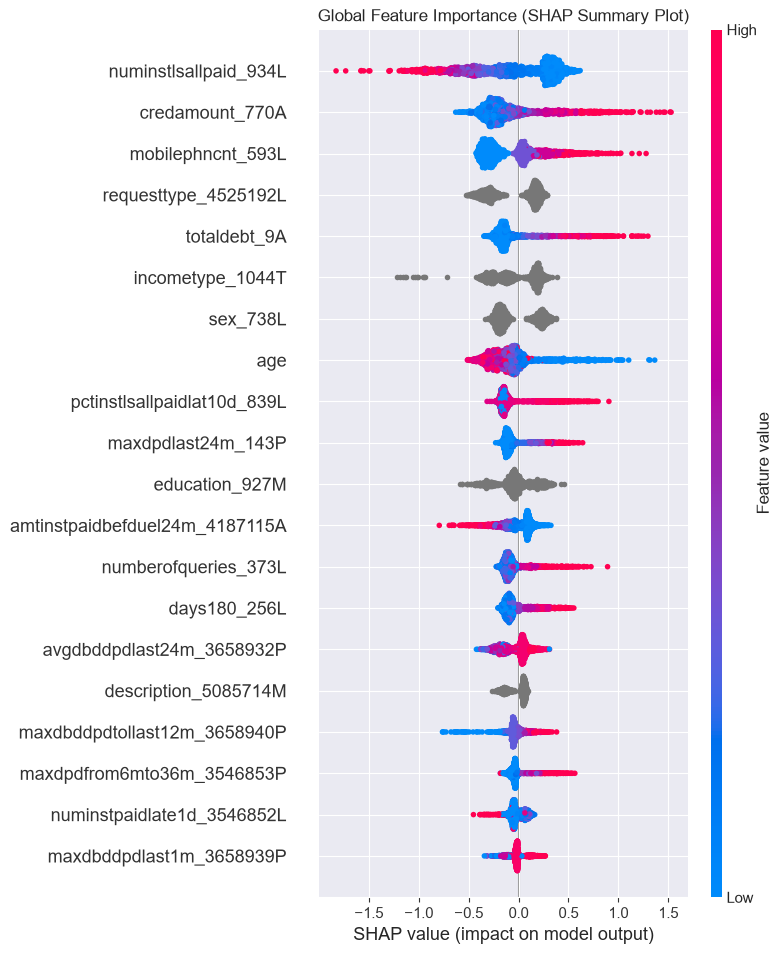

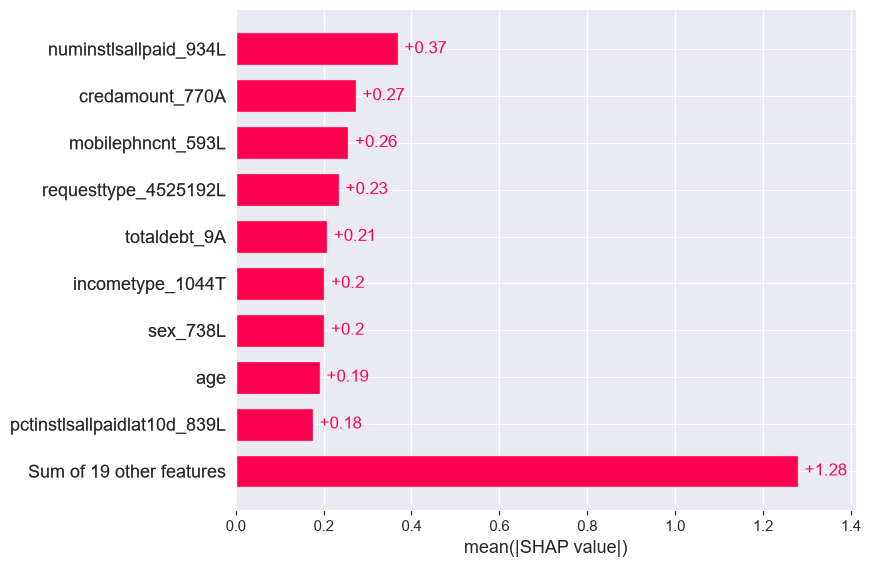

In [3]:
import shap
import matplotlib.pyplot as plt

print("\n--- ĐANG TÍNH TOÁN GLOBAL SHAP (TỔNG CỤC) ---")

# 1. Lấy mẫu ngẫu nhiên 2000 khách hàng từ tập Test để đại diện cho thị trường
X_sample = X_test.sample(2000, random_state=42)

# 2. Tính SHAP values cho toàn bộ mẫu này
shap_values_global = explainer.shap_values(X_sample)

# 3. Vẽ biểu đồ Summary Plot (Dạng Bee-swarm)
# Biểu đồ này cho biết: Biến nào quan trọng nhất + Xu hướng tác động (Tăng hay giảm rủi ro)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_global, X_sample, show=False)
plt.title("Global Feature Importance (SHAP Summary Plot)")
plt.show()

# 4. Vẽ biểu đồ Bar Plot (Chỉ xem độ quan trọng thuần túy)
plt.figure(figsize=(10, 8))
shap.plots.bar(explainer(X_sample))